In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from wordcloud import WordCloud, STOPWORDS
import numpy as np

train_path = r"C:\Users\Ramtin\Desktop\uni\quera Ai\deep learning\nlp\df_cleaned.csv"
df = pd.read_csv(train_path) 
display(df.head())

,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime,review_year,reviewText_clean,full_text
0,2,0,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400,2016,I have an older URC-WR7 remote and thought thi...,Cannot Learn I have an older URC-WR7 remote an...
1,5,0,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200,2016,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!? First time...
2,4,0,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000,2016,Got them and only 2 of them worked. company ca...,Works Good and programs easy. Got them and onl...
3,5,0,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600,2016,I got tired of the remote being on the wrong s...,Same as TWC remote I got tired of the remote b...
4,5,0,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600,2016,After purchasing cheap cords from another webs...,Good Quality Cord After purchasing cheap cords...


### 1. Rating Distribution & Class Imbalance Analysis

**Objective:**
To analyze the distribution of user ratings (overall scores from 1 to 5) and identify potential class imbalance issues that could bias downstream machine learning models.

**Rationale:**
Dataset skewness directly impacts model training. Recognizing class imbalance early dictates whether resampling techniques, loss-function weighting, or specific evaluation metrics (such as Micro F1-score which equals Accuracy) should be prioritized.

**Key Insights & Implications:**
* **Severe Imbalance:** The exploratory data analysis reveals a heavy left-skew in the dataset, with the vast majority of reviews concentrated in ratings 4 and 5, while ratings 1 through 3 represent a significantly smaller fraction.
* **Modeling Strategy:** To prevent classifiers from being biased toward the majority classes, unweighted baselines will be compared against models utilizing `class_weight='balanced'` or stratified sampling during training.


Overall rating distribution(%):
overall
1     9.887430
2     6.765171
3     9.683483
4    18.656072
5    55.007843
Name: proportion, dtype: float64


C:\Users\Ramtin\AppData\Local\Temp\ipykernel_18128\3789027482.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='overall', palette='viridis')


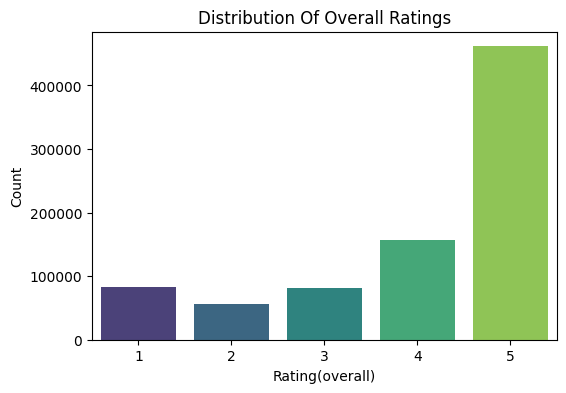

In [5]:
distribution = df['overall'].value_counts(normalize=True).sort_index()*100
print("Overall rating distribution(%):")
print(distribution)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='overall', palette='viridis')
plt.title('Distribution Of Overall Ratings')
plt.xlabel('Rating(overall)')
plt.ylabel('Count')
plt.show()

### 2. Sentiment-Based Word Clouds Analysis

**Objective:**
To visually inspect the most frequent and dominant terms across different sentiment polarities (Positive: 4-5 stars, Neutral: 3 stars, Negative: 1-2 stars) while handling class imbalance and noise words.

**Rationale & Implementation:**
Due to severe class imbalance in the dataset (heavily skewed towards 4 and 5-star ratings), a balanced sampling strategy ($1:1:1$) was applied prior to generating the Word Clouds. A custom stop-words list was constructed to filter out generic terms (e.g., *product*, *item*, *device*, *work*) while strictly **retaining negation words** (e.g., *not*, *no*, *never*), as negations fundamentally alter sentiment polarity. Collocations were also enabled (`collocations=True`) to capture phrase-level patterns.

**Key Insights:**
* **Positive Reviews (4-5 Stars):** Dominated by positive adjectives and descriptors such as *great*, *good*, *easy* (indicating ease of use), *fit*, *nice*, and *best*. These terms reflect high user satisfaction and seamless functionality.
* **Negative Reviews (1-2 Stars):** Interestingly, base positive words like *good*, *great*, and *fine* appear alongside prominent negation terms (most notably **`not`**), effectively inverting their polarity (e.g., "not good"). Additionally, terms like *issue*, *battery*, and *return* frequently emerge, pointing to specific hardware/performance pain points.
* **Neutral Reviews (3 Stars):** Characterized by mixed sentiment indicators, including terms like *problem*, *issue*, and conjunction/transition words such as *however*. The presence of *however* suggests conditional satisfaction—implying that while the product had certain drawbacks (*"it has issues, however..."*), it was still functionally acceptable. Modal verbs like *could* also appear, typically reflecting conditional framing or suggestions for improvement (e.g., *"it could be better"*).

[nltk_data] Error loading stopwords: <urlopen error _ssl.c:983: The
[nltk_data]     handshake operation timed out>


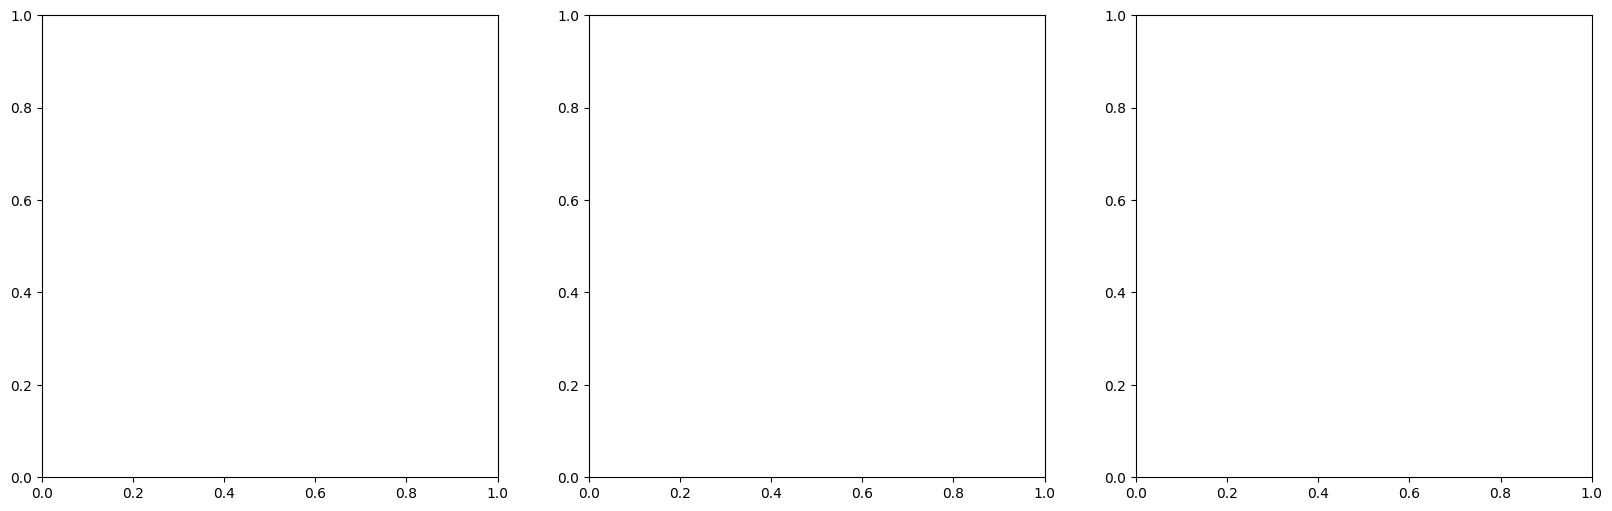

In [5]:
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
import matplotlib.pyplot as plt
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
negation_words = {'no', 'nor', 'not', 'never',"don't", "doesn't", "didn't","isn't", "wasn't", "won't","wouldn't", "couldn't", "shouldn't", 'dont', 'doesnt', 'didnt', 'isnt', 'wasnt', 'wont'}
stop_words -= negation_words
custom_stop_words = {'product', 'item', 'purchase', 'bought', 'buy', 'amazon', 'one', 'thing', 'stuff','use', 'used', 'using', 'get', 'got'}
stop_words.update(custom_stop_words)
pos_series = df[df['overall'].isin([4, 5])]['reviewText_clean'].dropna().astype(str)
neu_series = df[df['overall'] == 3]['reviewText_clean'].dropna().astype(str)
neg_series = df[df['overall'].isin([1, 2])]['reviewText_clean'].dropna().astype(str)
pos_text = " ".join(pos_series.sample(min(20000, len(pos_series)), random_state=42))
neu_text = " ".join(neu_series.sample(min(20000, len(neu_series)), random_state=42))
neg_text = " ".join(neg_series.sample(min(20000, len(neg_series)), random_state=42))
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
categories = [('Positive Reviews (4 & 5)', pos_text, 'Greens'),('Neutral Reviews (3)', neu_text, 'Blues'),('Negative Reviews (1 & 2)', neg_text, 'Reds')]




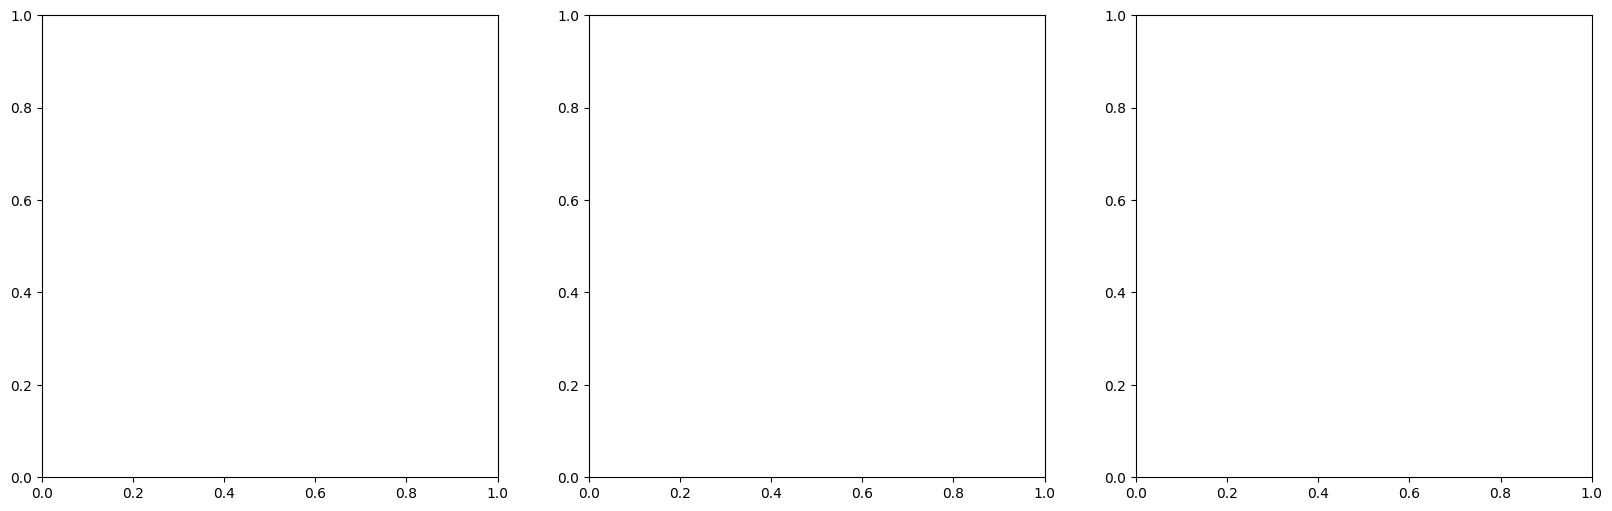

In [6]:
extra_stop = {'would', 'work', 'works', 'working', 'worked','time', 'also', 'need', 'make', 'well', 'much','even', 'still', 'see', 'first', 'two', 'take','look', 'back', 'way', 'come', 'find', 'give', 'say', 'put', 'headphone', 'keyboard', 'speaker', }
stop_words.update(extra_stop)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
categories = [('Positive Reviews (4 & 5)', pos_text, 'Greens'), ('Neutral Reviews (3)', neu_text, 'Blues'), ('Negative Reviews (1 & 2)', neg_text, 'Reds')]


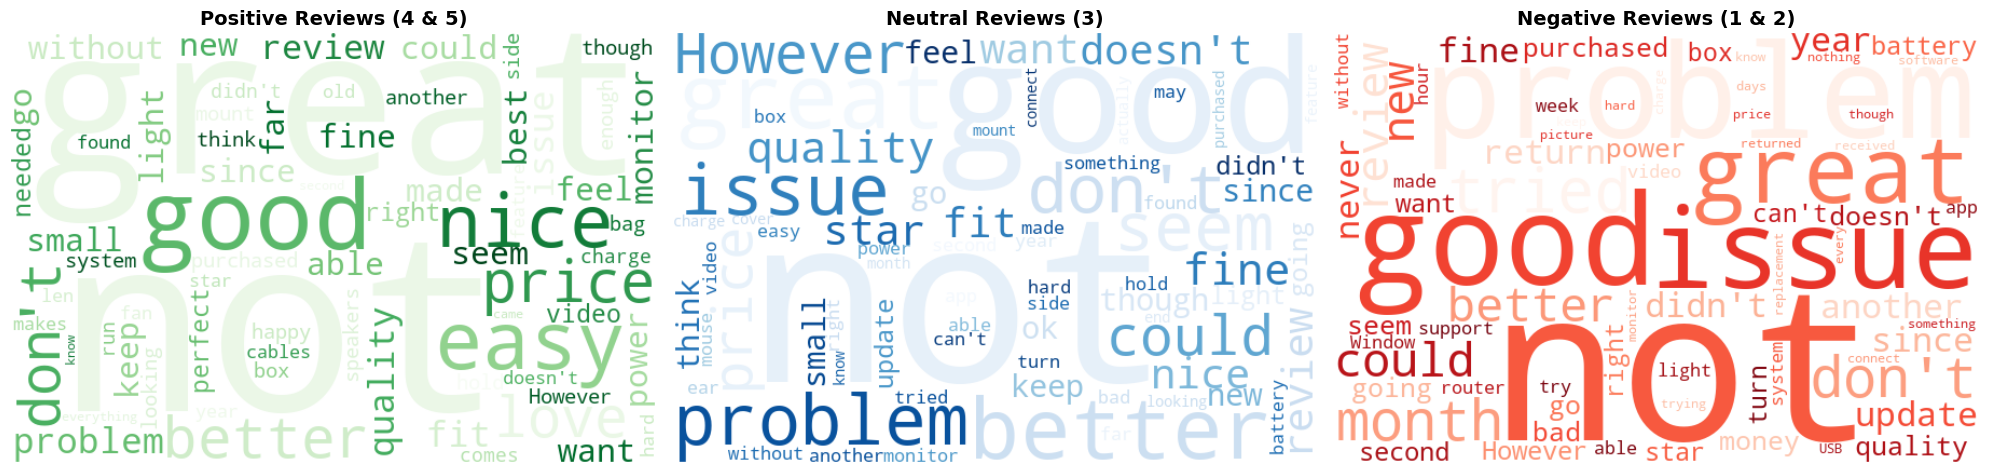

In [8]:
extra_stop_2 = {'really', 'like', 'device', 'case', 'camera', 'cable', 'phone', 'sound', 'tv', 'screen', 'laptop', 'unit','computer', 'headphones', 'speaker', 'drive', 'tablet','plug', 'button', 'day', 'set', 'lot', 'little', 'bit', 'around', 'long', 'no',}
stop_words.update(extra_stop_2)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
categories = [('Positive Reviews (4 & 5)', pos_text, 'Greens'),('Neutral Reviews (3)', neu_text, 'Blues'),('Negative Reviews (1 & 2)', neg_text, 'Reds')]
for ax, (title, text_data, cmap) in zip(axes, categories):
    wc = WordCloud(
        width=600, 
        height=400, 
        background_color='white',
        stopwords=stop_words, 
        colormap=cmap, 
        max_words=70,
        collocations=True,
        random_state=42
    ).generate(text_data)
    
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=14, weight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('eda_2_wordclouds_final.png', dpi=300, bbox_inches='tight')
plt.show()


### 3. Top Reviewers & Voting Behavior Analysis

**Objective:**
To identify the most influential reviewers based on cumulative helpful votes and ensure data integrity for missing reviewer names.

**Rationale & Implementation:**
Some entries lacked a valid `reviewerName`. To prevent data loss or anonymous aggregation issues, missing names were dynamically filled using their unique `reviewerID`. Furthermore, grouping was performed jointly on `['reviewerID', 'reviewerName_filled']` to avoid conflating distinct users who share common display names (e.g., "Amazon Customer").

**Key Insights:**
* The aggregation highlights power-users who contribute heavily to community feedback.
* Maintaining both ID and filled names ensures traceability and clean reporting without altering the underlying user identity space.

Top 10 Reviewers:
       reviewerName_filled  vote
98753         Benson Leung  4572
220280          Voltron00x  3181
129971             Obi Wan  3150
49224               nycebo  2978
293383            Mayra S.  2631
271144             Cthulhu  2607
39289          Chris Upton  2167
315437            Sally B.  1912
179221                  DJ  1867
161074       Mark A. Baker  1820


C:\Users\Ramtin\AppData\Local\Temp\ipykernel_11624\4287854476.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_reviewers, x='vote', y='reviewerName_filled', palette='magma')


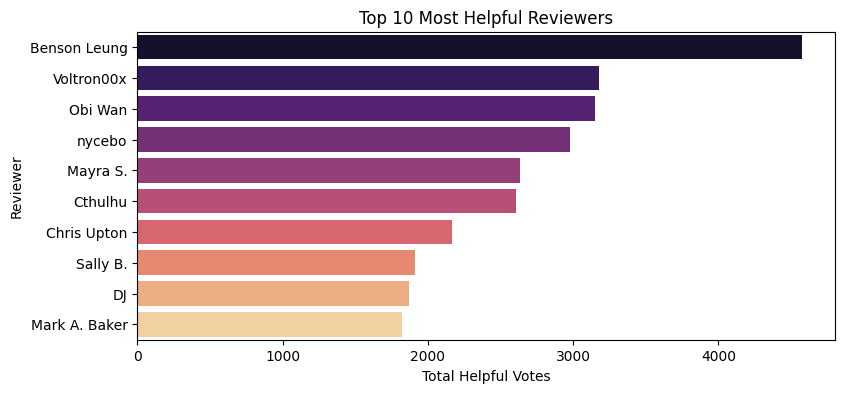

In [4]:
df['reviewerName_filled'] = df['reviewerName'].fillna(df['reviewerID'])
top_reviewers = (df.groupby(['reviewerID', 'reviewerName_filled'])['vote'].sum().reset_index().sort_values(by='vote', ascending=False).head(10))
print("Top 10 Reviewers:")
print(top_reviewers[['reviewerName_filled', 'vote']])
plt.figure(figsize=(9, 4))
sns.barplot(data=top_reviewers, x='vote', y='reviewerName_filled', palette='magma')
plt.title('Top 10 Most Helpful Reviewers')
plt.xlabel('Total Helpful Votes')
plt.ylabel('Reviewer')
plt.show()

### 4. Review Text Length Distribution & Truncation Strategy

**Objective:**
To examine the distribution of text character lengths across reviews, assess the presence of extreme outliers, and determine optimal sequence length boundaries for preprocessing and model ingestion.

**Rationale & Implementation:**
Text lengths in raw consumer reviews vary drastically—from single-word feedback to extensive, multi-paragraph essays. Feeding unbounded sequence lengths into vectorizers or transformer-based architectures can cause severe computational overhead and Out-Of-Memory (OOM) errors. We analyzed both raw and filtered distributions to identify statistical thresholds (e.g., 95th percentile).

**Key Insights & Strategic Decisions:**
* **Distribution Skew & Outliers:** The distribution is highly right-skewed. While the 95th percentile sits at approximately **1,733 characters**, extreme outliers stretch up to **29,146 characters**.
* **Filtering & Truncation Bounds:** A filtering window of **[10 to 1,500 characters]** preserves over 95% of meaningful semantic information while eliminating negligible noise (e.g., reviews with fewer than 10 characters) and capping excessively long inputs. This ensures uniform batch processing and prevents memory exhaustion during training.


95th Percentile: 1733 chars, 99th Percentile: 3399 chars, Max: 29146 chars


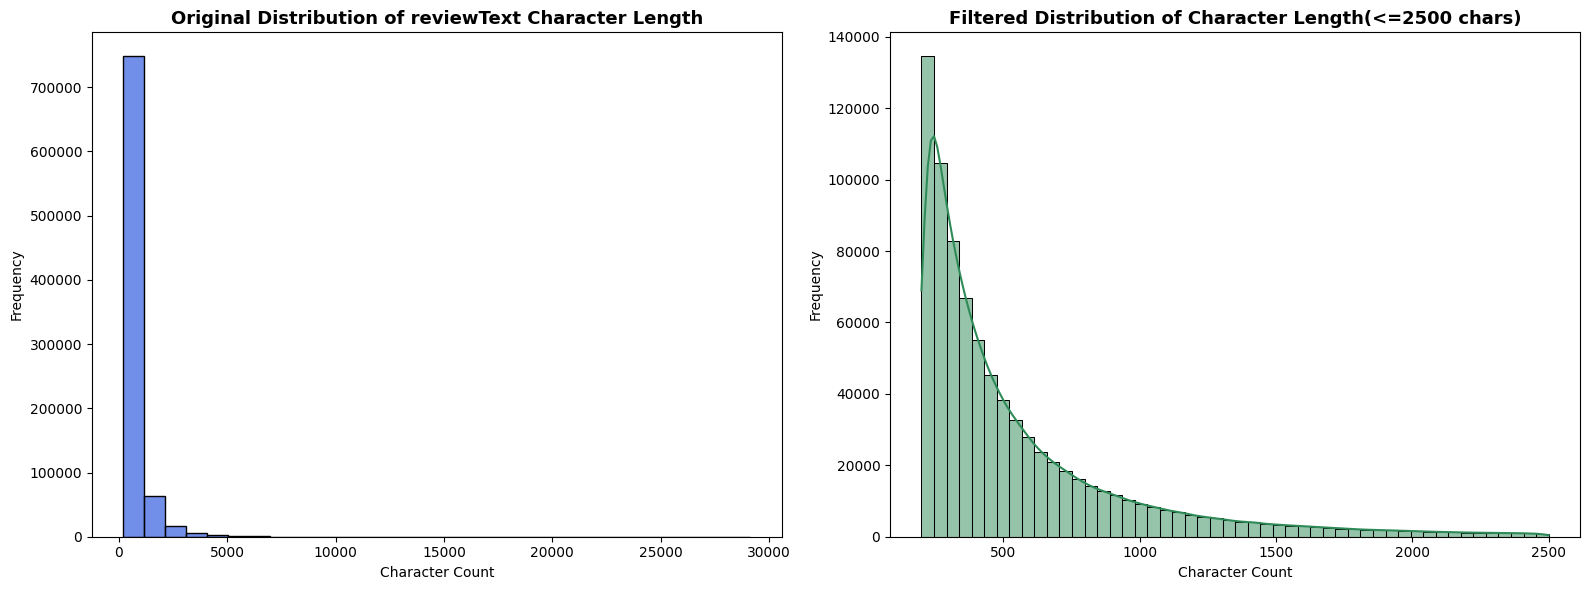

In [10]:
df['char_length'] = df['reviewText'].astype(str).apply(len)
p95 = np.percentile(df['char_length'], 95)
p99 = np.percentile(df['char_length'], 99)
print(f"95th Percentile: {p95:.0f} chars, 99th Percentile: {p99:.0f} chars, Max: {df['char_length'].max()} chars")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df['char_length'], bins=30, color='royalblue', ax=axes[0])
axes[0].set_title('Original Distribution of reviewText Character Length', fontsize=13, weight='bold')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')
filtered_df = df[df['char_length'] <= 2500]
sns.histplot(filtered_df['char_length'], bins=50, color='seagreen', kde=True, ax=axes[1])
axes[1].set_title('Filtered Distribution of Character Length(<=2500 chars)', fontsize=13, weight='bold')
axes[1].set_xlabel('Character Count')
axes[1].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

### 5. Top 5-Star Rated Products Analysis

**Objective:**
To identify the specific products that have accumulated the highest volume of 5-star ratings and analyze product-level customer satisfaction.

**Rationale & Implementation:**
The main review dataset contains product ASINs but lacks readable metadata. To enable meaningful analysis, we merged the reviews with `title_brand.csv` using the unique `asin` identifier. We then filtered for 5-star ratings (`overall == 5`) and aggregated the total volume of top ratings per product.

**Key Insights:**
* **Top Performers:** The rankings are led by widely adopted utility and peripheral items, such as the *SanDisk Ultra 64GB MicroSDXC card* (>13,000 5-star reviews) and high-volume charging cables (e.g., *AmazonBasics Lightning Cables*).
* **Consumer Patterns:** Essential, high-turnover everyday accessories consistently achieve large volumes of 5-star ratings due to widespread adoption and strong utility-to-price ratios.


In [12]:
title_brand_df = pd.read_csv(r"C:\Users\Ramtin\Desktop\uni\quera Ai\deep learning\nlp\title_brand.csv")
df = df.merge(title_brand_df[['asin', 'title', 'brand']], on='asin', how='left')
df['brand'] = df['brand'].fillna('Unknown')
df['title'] = df['title'].fillna('Unknown Title')
five_star_reviews = df[df['overall'] == 5]
top_10_products = (five_star_reviews.groupby(['asin', 'brand', 'title'], as_index=False).size().rename(columns={
        'brand': 'Brand Name',
        'title': 'Product Title',
        'size': '5-Star Review Count'})
    .sort_values(by='5-Star Review Count', ascending=False)
    .head(10)
)
top_10_products_table = top_10_products[['Brand Name', 'Product Title', '5-Star Review Count']].reset_index(drop=True)
top_10_products_table.index += 1
display(top_10_products_table)

,Brand Name,Product Title,5-Star Review Count
1,Cambridge Soundworks,OontZ Angle 3 Enhanced Stereo Edition IPX5 Spl...,1163
2,NETGEAR,NETGEAR N300 WiFi Range Extender (EX2700),659
3,Roku,Roku Streaming Stick (3600R) - HD Streaming Pl...,600
4,StarTech,StarTech USB 2.0 to SATA IDE Adapter (USB2SATA...,598
5,Logitech,Logitech M570 Wireless Trackball Mouse &ndash;...,552
6,Samsung,Samsung 850 EVO 500GB 2.5-Inch SATA III Intern...,529
7,NETGEAR,NETGEAR 5-Port Gigabit Ethernet Unmanaged Swit...,482
8,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,471
9,VideoSecu,VideoSecu ML531BE TV Wall Mount for Most 27&qu...,448
10,"Arlo Technologies, Inc",Arlo - Wireless Home Security Camera System | ...,433


### 6. Top Brands Analysis: Review Volume vs. Mean Rating

**Objective:**
To identify the most frequently reviewed brands across the dataset and evaluate aggregate customer satisfaction through their mean overall ratings.

**Rationale & Implementation:**
Evaluating individual products provides granular insights, but brand-level aggregation reveals overall consumer engagement and systemic product perception. We aggregated reviews by `brand`, computing both total review volume (`count`) and average score (`mean(overall)`), sorted by review volume.

**Key Insights:**
* **Volume Leaders:** Prominent global brands (such as *Apple*, *Samsung*, *Sony*, *SanDisk*, and *AmazonBasics*) lead the dataset in total customer engagement and feedback volume.
* **Rating Consistency:** Despite massive review counts (exceeding tens of thousands of reviews each), several high-volume brands (e.g., *SanDisk*) maintain strong average ratings ($\approx 4.3 - 4.5$), reflecting consistent customer satisfaction across their product portfolios.


In [ ]:
valid_brands_df = df[df['brand'].notna() & (df['brand'] != '') & (df['brand'] != 'Unknown')]
top_10_brand_names = valid_brands_df['brand'].value_counts().head(10).index
top_10_brands_stats = (valid_brands_df[valid_brands_df['brand'].isin(top_10_brand_names)].groupby('brand', as_index=False).agg(Total_Reviews=('overall', 'count'),Average_Rating=('overall', 'mean')).sort_values(by='Average_Rating', ascending=False).reset_index(drop=True))
top_10_brands_stats.index += 1
final_brand_table = top_10_brands_stats[['brand', 'Average_Rating', 'Total_Reviews']].rename(columns={
    'brand': 'Brand Name',
    'Average_Rating': 'Average Rating',
    'Total_Reviews': 'Total Reviews'})
display(final_brand_table)

,Brand Name,Average Rating,Total Reviews
1,Anker,4.244320,9860
2,AmazonBasics,4.201468,13213
3,Sabrent,4.028005,7320
4,SanDisk,3.958810,8400
5,Logitech,3.954061,17066
6,Samsung,3.941268,15409
7,Sony,3.938726,12436
8,TP-LINK,3.928681,9773
9,Asus,3.855550,11928
10,NETGEAR,3.836274,7085
